# Lab 3 — Байес теоремасы: медициналық тест

Адам К вирусын анықтау үшін қан талдауын тапсырды.

**Белгілеулер:** $Z$ — адам К вирусын жұқтырған; $+$ — тест нәтижесі оң.

## Data

| Шарт | Белгілеу | Мәні |
|---|---|---|
| Жалпы халықта әр 10 000-ның 1-еуі ауру (А бөлімі) | $P(Z)_A$ | $0.0001$ |
| Ақтау тойынан қайтқандарда әр 200-дің 1-еуі ауру (B бөлімі) | $P(Z)_B$ | $0.005$ |
| Жалған оң нәтиже (false positive) — 1% | $P(+\mid \neg Z)$ | $0.01$ |
| Жалған теріс нәтиже (false negative) — 0% | $P(-\mid Z)$ | $0$ |
| Тест сезімталдығы | $P(+\mid Z)=1-P(-\mid Z)$ | $1$ |
| Адамның тест нәтижесі | — | **оң (+)** |

**Табу керек:** $P(Z\mid+)$ — тест оң болғанда аурудың нақты болу ықтималдығы (А және B бөлімдері үшін жеке-жеке).

In [6]:
import numpy as np
import matplotlib.pyplot as plt

def bayes(prior, sens=1.0, false_pos=0.01):
    """P(Z|+) = P(+|Z)P(Z) / [P(+|Z)P(Z) + P(+|~Z)P(~Z)]"""
    return sens * prior / (sens * prior + false_pos * (1 - prior))


## А бөлімі — Жалпы халық

Жалпы халық арасында әрбір 10 000 адамның 1-еуінде К вирусы бар, яғни априорлық ықтималдық $P(Z) = 1/10000 = 0.0001$.

Байес теоремасы бойынша, тест оң болғанда аурудың нақты болу ықтималдығы:

$$
P(Z \mid +) = \frac{P(+ \mid Z)\, P(Z)}{P(+ \mid Z)\, P(Z) + P(+ \mid \neg Z)\, P(\neg Z)}
$$

Төменде осы формуланы Python-мен есептейміз және 1 млн адамға имитация арқылы тексереміз.

P(Z|+) = 0.009902  →  0.99%
Имитация P(Z|+) = 0.009672


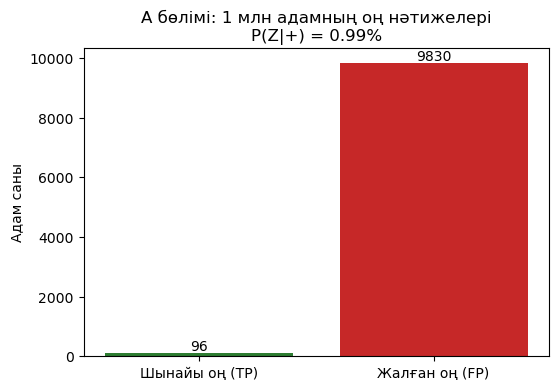

In [ ]:
prior_a = 1 / 10_000
post_a = bayes(prior_a)
print(f"P(Z|+) = {post_a:.6f}  →  {post_a*100:.2f}%")

# 1mln check
rng = np.random.default_rng(42)
N = 1_000_000
infected = rng.random(N) < prior_a
positive = np.where(infected, True, rng.random(N) < 0.01)
print(f"Имитация P(Z|+) = {infected[positive].mean():.6f}")

# Шынайы оң vs жалған оң
tp = infected.sum()
fp = (positive & ~infected).sum()
plt.figure(figsize=(6, 4))
plt.bar(["Шынайы оң (TP)", "Жалған оң (FP)"], [tp, fp], color=["#2e7d32", "#c62828"])
plt.title(f"А бөлімі: 1 млн адамның оң нәтижелері\nP(Z|+) = {post_a*100:.2f}%")
plt.ylabel("Адам саны")
for x, y in enumerate([tp, fp]):
    plt.text(x, y, f"{y}", ha="center", va="bottom")
plt.show()


**А бөлімінің нәтижесі:** $P(Z\mid+) \approx 0.0099 = 0.99\%$.

Неге оң тест «99% ауру» дегенді білдірмейді? Ауру өте сирек: 1 млн адамның ~100-і ауру, олардың бәрі оң нәтиже береді (жалған теріс = 0%). Ал ауруы жоқ ~999 900 адамның ~1%-ы (~10 000) **жалған оң** береді. Яғни оң нәтижелердің ішінде жалғандары шынайыларынан ~100 есе көп — оң тест иесінің нақты ауру болу шансы небәрі ~1% (**base rate fallacy**).

## B бөлімі — Жаңа априорлық ақпарат (Ақтау тойы)

Адам жақында Ақтауда өткен досының тойына қатысқан. Ақтауға барып келгендердің әрбір 200-інің 1-еуі вирус жұқтырады: $P(Z) = 1/200 = 0.005$.

Тест сипаттамалары **өзгеріссіз** ($P(+\mid Z)=1$, $P(+\mid\neg Z)=0.01$), сондықтан А бөлімінің коды қайта қолданылады — өзгерген параметр тек **априор** $P(Z)$ (50 есе жоғары).

P(Z|+) = 0.334448  →  33.44%
Имитация P(Z|+) = 0.342999


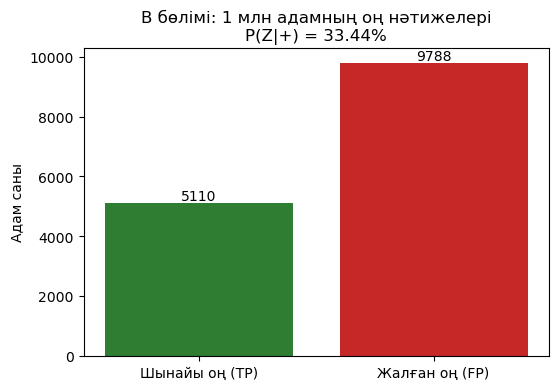

In [8]:
prior_b = 1 / 200
post_b = bayes(prior_b)
print(f"P(Z|+) = {post_b:.6f}  →  {post_b*100:.2f}%")

rng = np.random.default_rng(42)
infected = rng.random(N) < prior_b
positive = np.where(infected, True, rng.random(N) < 0.01)
print(f"Имитация P(Z|+) = {infected[positive].mean():.6f}")

tp = infected.sum()
fp = (positive & ~infected).sum()
plt.figure(figsize=(6, 4))
plt.bar(["Шынайы оң (TP)", "Жалған оң (FP)"], [tp, fp], color=["#2e7d32", "#c62828"])
plt.title(f"B бөлімі: 1 млн адамның оң нәтижелері\nP(Z|+) = {post_b*100:.2f}%")
plt.ylabel("Адам саны")
for x, y in enumerate([tp, fp]):
    plt.text(x, y, f"{y}", ha="center", va="bottom")
plt.show()


## Салыстыру: А және B бөлімдері, априордың (prior) рөлі

| Бөлім | $P(Z)$ prior | $P(+\mid Z)$ | $P(+\mid\neg Z)$ | $P(Z\mid+)$ posterior |
|---|---|---|---|---|
| А — жалпы халық | 0.01% | 1 | 0.01 | **0.99%** |
| B — Ақтау тойы | 0.5% | 1 | 0.01 | **33.44%** |

Тест дәлдігі бірдей, бірақ prior ×50 өскенде posterior ×34 өсті. График бұл байланысты көрсетеді: $P(Z\mid+)$ аурудың таралуына күшті тәуелді.

**Түсіндірме.** Байес формуласында жалған оңдардың үлесі $P(+\mid\neg Z)\,P(\neg Z)$ prior-ға пропорционал. Ауру сирек кезде (А) жалған оңдар шынайы оңдарды басып кетеді; қауіп тобында (B) вирус жиі кездесетіндіктен, шынайы оңдар басым бола бастайды. Сондықтан **априорлық ықтималдық** — тесттің оң нәтижесін дұрыс бағалау үшін шешуші рөл атқарады: бірдей дәл тест әртүрлі топта әртүрлі қорытынды береді.

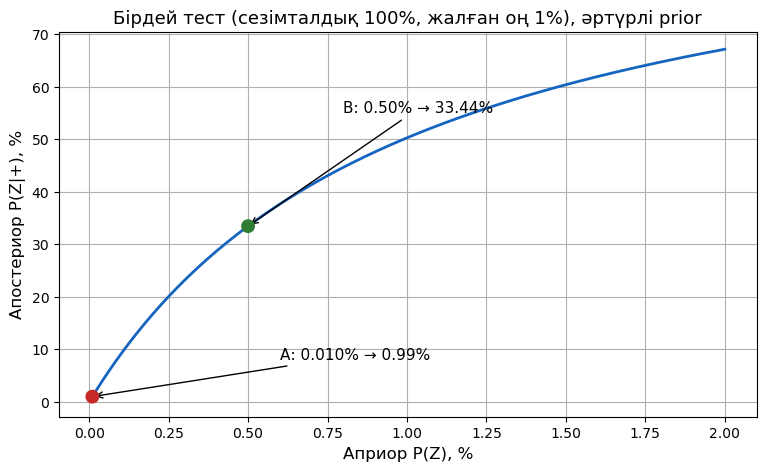

А → B: prior ×50, posterior ×34


In [9]:
priors = np.linspace(0.00005, 0.02, 400)
posteriors = bayes(priors)

plt.figure(figsize=(9, 5))
plt.plot(priors * 100, posteriors * 100, color="#1565c0", lw=2)
plt.scatter([prior_a * 100, prior_b * 100], [post_a * 100, post_b * 100],
            color=["#c62828", "#2e7d32"], zorder=5, s=80)
plt.annotate(f"А: {prior_a*100:.3f}% → {post_a*100:.2f}%",
             (prior_a * 100, post_a * 100), xytext=(0.6, 8),
             arrowprops=dict(arrowstyle="->"), fontsize=11)
plt.annotate(f"B: {prior_b*100:.2f}% → {post_b*100:.2f}%",
             (prior_b * 100, post_b * 100), xytext=(0.8, 55),
             arrowprops=dict(arrowstyle="->"), fontsize=11)
plt.xlabel("Априор P(Z), %", fontsize=12)
plt.ylabel("Апостериор P(Z|+), %", fontsize=12)
plt.title("Бірдей тест (сезімталдық 100%, жалған оң 1%), әртүрлі prior", fontsize=13)
plt.grid(True)
plt.show()

print(f"А → B: prior ×{(prior_b/prior_a):.0f}, posterior ×{(post_b/post_a):.0f}")


## Қорытынды

Байес теоремасы априорлық ықтималдықты $P(Z)$ жаңа дәлел (оң тест) арқылы апостериорлық $P(Z\mid+)$-ке жаңартады:

$$P(Z\mid+) = \frac{P(+\mid Z)}{P(+)}\,P(Z)$$

- Сирек ауруда (кіші prior) тіпті өте дәл тесттің оң нәтижесі де төмен ықтималдық береді (А — 0.99%).
- Қауіп тобында (үлкен prior) сол тест әлдеқайда жоғары ықтималдық береді (B — 33.44%).

Практикалық мағынасы: медицинада тесттің оң нәтижесін бағалағанда аурудың таралу жиілігі мен науқастың тәуекел факторларын (эпидемиологиялық ақпарат) міндетті түрде ескеру керек.